# SE201 Week 2 — The forward pass

Run a small neural network by hand, then in code, and get the same answers.

This notebook does the **forward pass only**.
There is no training here. Parts 1 and 2 use weights chosen by hand;
Part 3 downloads weights that someone else trained. Either way we only
ever run the network forwards.

Parts 1 and 2 need only **numpy** and **torch**.
Part 3 downloads a real model, so it needs **transformers** and a connection.

#### *Same process as the worksheet we did in class in Week 3 (j=just via code instead of manually calculating)
## The problem

Two features describing a proposed change to a codebase:

* `x1`: files touched 
* `x2`: lines changed, in hundreds, **rounded down** to the nearest hundred. 230 lines gives `x2 = 2` 

The network should return true, that the change is reviewable in one sitting, if:
```
2 <= x1 <= 6      and      1 <= x2 <= 5
```
In raw counts that is 2 to 6 files and 100 to 599 lines, both inclusive. 

The upper bound is 599 rather than 500 because `x2` is rounded down: every
count from 500 to 599 gives `x2 = 5`.

That region is a rectangle in the plane. No single neuron can do this: a
neuron's boundary is one straight line. 

Instead, we use four hidden units, one per edge, and an
output unit that fires only when all four agree.

## The network

```
h1 = step( x1 - 2)      at least 2 files
h2 = step(-x1 + 6)      at most 6 files
h3 = step( x2 - 1)      at least 100 lines
h4 = step(-x2 + 5)      at most 599 lines

y  = step(h1 + h2 + h3 + h4 - 3.5)      all four
```

Written with the bias trick: append a constant 1 to each layer's input and
the bias becomes the last column of the weight matrix.

$$
\mathbf{x}=\begin{bmatrix}x_1\\x_2\\1\end{bmatrix},\qquad
\mathbf{W}_1=\begin{bmatrix}
1&0&-2\\-1&0&6\\0&1&-1\\0&-1&5\end{bmatrix},\qquad
\mathbf{w}_2=\begin{bmatrix}1&1&1&1&-3.5\end{bmatrix}
$$

The threshold of 3.5 on the output neuron means it is positive only when every hidden neuron outputs a 1.

## Part 1 — numpy

In [1]:
import numpy as np

# The bias is the LAST COLUMN of each matrix, so every layer is one matmul.
W1 = np.array([[ 1.0,  0.0, -2.0],      # h1:  x1 >= 2
               [-1.0,  0.0,  6.0],      # h2:  x1 <= 6
               [ 0.0,  1.0, -1.0],      # h3:  x2 >= 1
               [ 0.0, -1.0,  5.0]])     # h4:  x2 <= 5

w2 = np.array([1.0, 1.0, 1.0, 1.0, -3.5])   # AND of the four

print("W1 shape", W1.shape, " w2 shape", w2.shape)

W1 shape (4, 3)  w2 shape (5,)


`W1` is 4 x 3: **one row per neuron**, and one column per input plus the bias.

The two zeros in the `x2` column of rows 1 and 2 mean
those neurons do not look at that feature. 

`h1` and `h2` are about files only and `h3` and `h4` are about lines of code only.

In [2]:
def step(z):
    """step(z) = 1 when z >= 0, else 0.  Applied elementwise."""
    return (np.asarray(z) >= 0).astype(int)


def augment(v):
    """Append the constant 1 that the bias column multiplies."""
    return np.append(v, 1.0)


def forward(x1, x2):
    x = augment([x1, x2])          # Append the 1
                                   # @ is matrix-vector multiply
    z = W1 @ x                     # 4 numbers, one per hidden unit
    h = step(z)
    z_out = w2 @ augment(h)        # Append the 1
    y = int(step(z_out))
    return z, h, z_out, y

forward(4, 3)

(array([2., 2., 2., 2.]), array([1, 1, 1, 1]), 0.5, 1)

### The three rows from the worksheet

Check these against what you worked out by hand.

In [3]:
CASES = [(4, 3), (7, 3), (4, 0)]

print("  x1  x2 |           z            |      h       | z_out |  y")
print("  " + "-" * 62)
for x1, x2 in CASES:
    z, h, z_out, y = forward(x1, x2)
    print("  %2d  %2d | %-22s | %-12s | %5.1f |  %d"
          % (x1, x2, z.tolist(), h.tolist(), z_out, y))

  x1  x2 |           z            |      h       | z_out |  y
  --------------------------------------------------------------
   4   3 | [2.0, 2.0, 2.0, 2.0]   | [1, 1, 1, 1] |   0.5 |  1
   7   3 | [5.0, -1.0, 2.0, 2.0]  | [1, 0, 1, 1] |  -0.5 |  0
   4   0 | [2.0, 2.0, -1.0, 5.0]  | [1, 1, 0, 1] |  -0.5 |  0


When a change is rejected, exactly which hidden unit came out 0 says which
edge of the box it fell outside. 

This does not work for deep networks in general because the output is not so clear-cut.

In [4]:
REASON = ["too few files", "too many files", "too few lines", "too many lines"]

for x1, x2 in CASES:
    _, h, _, y = forward(x1, x2)
    if y == 1:
        print("(%d, %d)  accepted" % (x1, x2))
    else:
        why = [REASON[i] for i in range(4) if h[i] == 0]
        print("(%d, %d)  rejected: %s" % (x1, x2, ", ".join(why)))

(4, 3)  accepted
(7, 3)  rejected: too many files
(4, 0)  rejected: too few lines


### Seeing the region

One dot per whole-number input, filled where the network accepts. The
rectangle should be exactly the box in the rule.

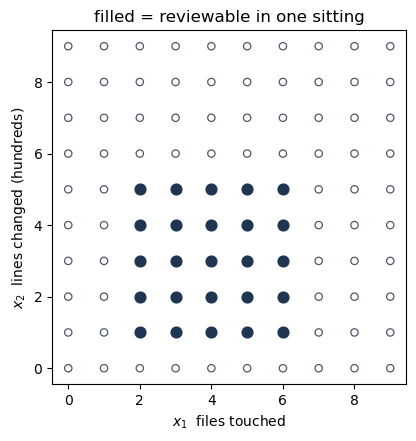

In [5]:
import matplotlib.pyplot as plt

xs = [(a, b) for a in range(0, 10) for b in range(0, 10)]
acc = [p for p in xs if forward(*p)[3] == 1]
rej = [p for p in xs if forward(*p)[3] == 0]

fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.scatter([p[0] for p in rej], [p[1] for p in rej], s=28,
           facecolors="none", edgecolors="#4E5866", linewidths=0.9)
ax.scatter([p[0] for p in acc], [p[1] for p in acc], s=60, color="#1F3552")
ax.set_aspect("equal")
ax.set_xlabel("$x_1$  files touched")
ax.set_ylabel("$x_2$  lines changed (hundreds)")
ax.set_title("filled = reviewable in one sitting")
plt.show()

## Part 2 — PyTorch
PyTorch keeps the bias **separate** from the weight matrix rather than folding
it into an extra column. 

`nn.Linear(3, 4)` holds a 4 x 3 `weight` and a 4-element `bias`, and computes `weight @ x + bias`.

So our augmented `W1` splits in two: its first two columns become the `weight`
of `nn.Linear(2, 4)`, and its last column becomes the `bias`. The bias trick and
a separate bias are two ways of writing the same layer, which is why the code
below copies the columns across separately.

Torch uses the `Tensor` type to store vectors and matrices.

In [6]:
#!pip3 install torch
import torch
import torch.nn as nn

W1_t = torch.tensor(W1, dtype=torch.float32)
w2_t = torch.tensor(w2, dtype=torch.float32)
print('Layer1 weight with bias\n', W1_t)
print()
layer1 = nn.Linear(2, 4)     # 2 inputs, 4 neurons
layer2 = nn.Linear(4, 1)     # 4 inputs, 1 neuron

with torch.no_grad():                       # we are setting weights, not learning
    layer1.weight.copy_(W1_t[:, :2])        # first two columns
    layer1.bias.copy_(W1_t[:, 2])           # last column
    layer2.weight.copy_(w2_t[:4].reshape(1, 4))
    layer2.bias.copy_(w2_t[4:])

print("layer1.weight\n", layer1.weight)
print("layer1.bias\n", layer1.bias)

Layer1 weight with bias
 tensor([[ 1.,  0., -2.],
        [-1.,  0.,  6.],
        [ 0.,  1., -1.],
        [ 0., -1.,  5.]])

layer1.weight
 Parameter containing:
tensor([[ 1.,  0.],
        [-1.,  0.],
        [ 0.,  1.],
        [ 0., -1.]], requires_grad=True)
layer1.bias
 Parameter containing:
tensor([-2.,  6., -1.,  5.], requires_grad=True)


Convert the input data into a `Tensor`. Note that PyTorch takes a **whole batch at once**: three inputs
go in as a 3 x 2 tensor and three answers come out.

In [7]:
def forward_nn(batch):
    """batch is an (N, 2) tensor of inputs; returns an (N,) tensor of answers."""
    # layer1(batch) is the pre-activation
    # layer1(batch) >= 0 is the step activation function
    h = (layer1(batch) >= 0).float()
    # layer2(h) is the pre-activation
    # layer2(h) >= 0 is the step activation function
    return (layer2(h).squeeze(1) >= 0).int()

# Convert our batch into torch's tensor type
batch = torch.tensor([[float(a), float(b)] for a, b in CASES])
print(batch)
print(forward_nn(batch))

tensor([[4., 3.],
        [7., 3.],
        [4., 0.]])
tensor([1, 0, 0], dtype=torch.int32)


## Part 3 — a real model, downloaded from a hub

Parts 1 and 2 used weights we chose by hand. 

You can download pre-trained models from a model hub. Hugging Face is the largest, with Kaggle Models,
PyTorch Hub and NVIDIA NGC also popular.

Go to <https://huggingface.co/models>, pick the task in
the left-hand filter, **text classification** in this case. Read the model card to find out what it was trained on,
what the labels mean, its licence, and its size, etc.

The one below is the model Hugging Face's own `sentiment-analysis` pipeline
uses by default.

**<https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english>**

Open that page and look at the **Files and versions** tab. You will see
`config.json` and `model.safetensors`, which are the architecture and the weights.

This part needs `transformers` and a working network connection. The download
is about 270 MB the first time (66.96 million parameters at four bytes each)
and is then cached under `~/.cache/huggingface`. You can delete this later if you like.

In [ ]:
# Run once if needed:
#!pip3 install transformers

from transformers import (AutoConfig, AutoTokenizer,
                          AutoModelForSequenceClassification)

MODEL_ID = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"

### The architecture arrives before the weights

`AutoConfig` fetches `config.json` on its own — a few kilobytes. It is worth
looking at first, because it answers the Q1 questions from the worksheet about
a model you did not build.

In [ ]:
config = AutoConfig.from_pretrained(MODEL_ID)

print("class      ", config.architectures)
print("layers     ", config.num_hidden_layers)
print("width      ", config.hidden_size, "numbers per token")
print("labels     ", config.id2label)
# why does it download so fast? --> Ans: Bc we are only downloading the architecture (e.g. The number of hidden units & Which activation function to use) (no weights/ training yet)

class       ['DistilBertForSequenceClassification']
layers      6
width       768 numbers per token
labels      {0: 'NEGATIVE', 1: 'POSITIVE'}


`id2label` converts the classifier's output, which is a
vector of numbers, to something we can read.

This model just classifies positive and negative sentiment. An LLM's equivalent output will need to be de-tokenised.

In [10]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_ID)
model.eval()      # inference mode: dropout off (no_grad below handles gradients)

total = sum(p.numel() for p in model.parameters())
head = sum(p.numel() for p in model.classifier.parameters())
print("parameters in the whole model: %d" % total)
print("parameters in the last layer:  %d" % head)
print("the last layer is %.4f%% of the model" % (100 * head / total))

parameters in the whole model: 66955010
parameters in the last layer:  1538
the last layer is 0.0023% of the model


### Viewing the architecture as text

`print(model)` walks the module tree. You do not need to understand all of it yet.

* Linear layers are the same layers we have been studying in toy examples.

In [11]:
print(model)

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): MultiHeadSelfAttention(
            (dropout): Dropout(p=0.1, inplace=False)
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)
 

In [12]:
# The head on its own, with the shapes spelled out.
print("pre_classifier :", model.pre_classifier)
print("classifier     :", model.classifier)
print()
for name, p in model.classifier.named_parameters():
    print("classifier.%-6s shape %-12s %d numbers" % (name, tuple(p.shape), p.numel()))

pre_classifier : Linear(in_features=768, out_features=768, bias=True)
classifier     : Linear(in_features=768, out_features=2, bias=True)

classifier.weight shape (2, 768)     1536 numbers
classifier.bias   shape (2,)         2 numbers


`Linear(in_features=768, out_features=2)` is a weight matrix of shape 2 x 768
and a bias of length 2 — one row per output class, one column per input
feature, which is the layout from the worksheet. 

2 x 768 + 2 = 1538.

The output layer you did by hand was `Linear(4, 1)`: 1 x 4 + 1 = 5. 

`torchinfo` gives a layered table with output shapes, which is easier to read
than the module tree when you only care about one part.

In [13]:
#!pip3 install torchinfo
try:
    from torchinfo import summary
    print(summary(model.classifier, input_size=(1, config.hidden_size), verbose=0))
except ImportError:
    print("torchinfo not installed — pip install torchinfo")

torchinfo not installed — pip install torchinfo


### Viewing it graphically

Export the model to ONNX and open the file in [Netron](https://netron.app). It
runs in the browser, with nothing to install. Zoom in on the far end of the
graph and you will find the same two `Linear` layers the text view just listed.

The export needs `onnx` and `onnxscript`, so the cell below is optional.

In [50]:
#!pip3 install onnx onnxscript

In [14]:
# Optional: the full graph, for Netron.  Needs  pip install onnx onnxscript
try:
    import torch
    example = tokenizer("a short sentence", return_tensors="pt")
    torch.onnx.export(model, (example["input_ids"], example["attention_mask"]),
                      "sst2.onnx",
                      input_names=["input_ids", "attention_mask"],
                      output_names=["logits"])
    print("wrote sst2.onnx — open it at https://netron.app")
except Exception as exc:
    print("skipped:", type(exc).__name__, exc)
    print("pip install onnx onnxscript  if you want the Netron view")

/Users/breann/anaconda3/lib/python3.11/site-packages/transformers/models/distilbert/modeling_distilbert.py:223: TracerWarning: torch.tensor results are registered as constants in the trace. You can safely ignore this warning if you use this function to create tensors out of constant variables that would be the same every time you call this function. In any other case, this might cause the trace to be incorrect.
  mask, torch.tensor(torch.finfo(scores.dtype).min)


================ Diagnostic Run torch.onnx.export version 2.0.1 ================
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================

skipped: OnnxExporterError Module onnx is not installed!
pip install onnx onnxscript  if you want the Netron view


### The forward pass

Same three steps as Part 1: turn the input into numbers, push it through the
layers, read the output. The only new step is the **tokenizer**, which turns
text into the integer IDs the embedding layer expects — that was Week 1's
material.

In [ ]:
import torch

texts = [
    "The refactor is clean and the tests all pass.",
    "This patch breaks the build and nobody reviewed it.",
]

batch = tokenizer(texts, padding=True, return_tensors="pt")
print("input_ids", tuple(batch["input_ids"].shape), "  (2 sentences, padded to the same length)")

with torch.no_grad():                 # no training here, so no gradients
    logits = model(**batch).logits

print("logits\n", logits)

#tensors are important in telling which tokens are important etc. (act as the containers that store the mathematical values representing that importance)

input_ids (2, 14)   (2 sentences, padded to the same length)
logits
 tensor([[-1.8578,  1.9317],
        [ 4.4338, -3.5777]])


The two numbers per row are **logits** — raw scores, one per class, straight out
of the last `Linear`.

Softmax turns a row of scores into probabilities that sum
to 1. 

It is very similar to the sigmoid, but for more than two outputs.

In [55]:
probs = logits.softmax(dim=-1)

for text, row in zip(texts, probs):
    best = int(row.argmax())
    print("%-52s %-8s %.3f" % (text[:50], model.config.id2label[best], row[best]))

The refactor is clean and the tests all pass.        POSITIVE 0.978
This patch breaks the build and nobody reviewed it   NEGATIVE 1.000


### The last layer is the network you did by hand

The body turns each sentence into one vector of 768 numbers. 

The classifier is a simple linear layer of the kind you computed on paper.

In [56]:
import torch.nn as nn

with torch.no_grad():
    body_out = model.distilbert(**batch).last_hidden_state
    sentence = body_out[:, 0]                          # the [CLS] position
    pooled = nn.ReLU()(model.pre_classifier(sentence))
    # extract the weights and biases from the model
    W = model.classifier.weight       # 2 x 768
    b = model.classifier.bias         # 2
    by_hand = pooled @ W.T + b        # exactly W x + b, one row per sentence

print("by hand\n", by_hand)
print("model  \n", logits)
assert torch.allclose(by_hand, logits, atol=1e-4), "the hand-computed layer disagrees"
print("\nthe hand-computed last layer matches the model's output")

by hand
 tensor([[-1.8578,  1.9317],
        [ 4.4338, -3.5777]])
model  
 tensor([[-1.8578,  1.9317],
        [ 4.4338, -3.5777]])

the hand-computed last layer matches the model's output


It is `W x + b` applied to a 768-number input instead of a 2-number one, with weights that were learned rather than chosen.

## Some things to try

**1. Move an edge.** In `W1`, change the `6` in the second row to `8`, re-run
the cells below it, and look at the picture again. Which edge moved? Which of
the three worksheet cases changes answer?

**2. Try another model.** In Part 3, change `MODEL_ID` to another text classifier
and re-run. `config.id2label` will change, and so may the attribute
names in the last cell. What does that model card say the labels mean?

